# Boucles d'hystérésis en traction-compression cyclique

Comparaison écrouissage isotrope (Voce), cinématique (Prager) et combiné.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(os.path.join('..', 'src')))
import numpy as np, matplotlib.pyplot as plt
import j2gauss                      # active jax_enable_x64
from j2gauss import Params
from j2gauss.driver import run_mixed, UNIAXIAL, TENSION_SHEAR
%matplotlib inline

Text(0, 0.5, 'sigma11 (MPa)')

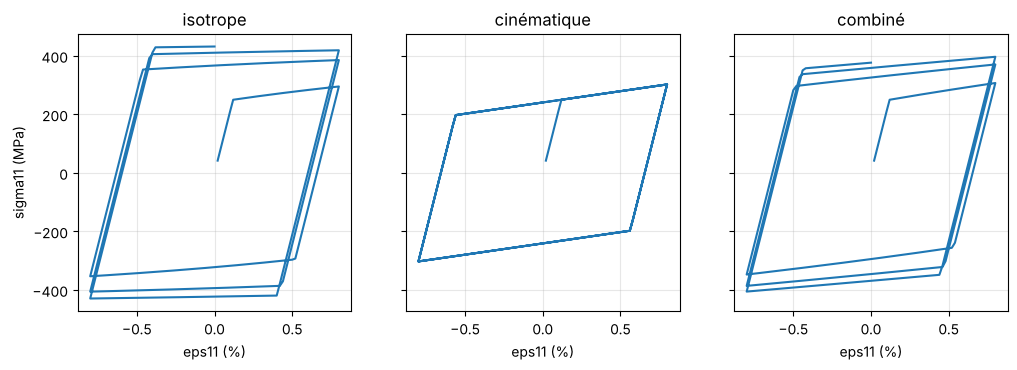

In [2]:
amp = 0.008
q = np.linspace(0, 1, 41)[1:]
e11 = amp * np.tile(np.concatenate([q, 1-q, -q, -1+q]), 3)
path = np.zeros((e11.size, 6)); path[:, 0] = e11
mats = {'isotrope': Params(H=500., Q=150., b=50.),
        'cinématique': Params(H=0., C=8000.),
        'combiné': Params(H=500., Q=100., b=50., C=4000.)}
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
for ax, (k, P) in zip(axes, mats.items()):
    res = run_mixed(path, UNIAXIAL, P)
    ax.plot(e11 * 100, res['sigma'][:, 0]); ax.set_title(k); ax.set_xlabel('eps11 (%)')
    ax.grid(alpha=.3)
axes[0].set_ylabel('sigma11 (MPa)')

* **Isotrope** : la limite d'élasticité croît dans les deux sens ; la boucle s'élargit puis se stabilise quand $R(p)$ sature.
* **Cinématique** : le domaine élastique garde sa taille $2\sigma_y$ mais se translate ; la plastification en compression commence avant $-\sigma_y$ (effet Bauschinger) et la boucle est stable dès le premier cycle.
* **Combiné** : les deux effets.